In [3]:
import pandas as pd
import numpy as np

np.random.seed(42)

n_rows = 500
data = {
    'Employee_ID': np.arange(1001, 1001 + n_rows),
    'Base_Salary': np.random.normal(60000, 15000, n_rows).round(2),
    'Bonus_Pct': np.random.uniform(0.05, 0.25, n_rows).round(4),
    'Account_Balance': np.random.exponential(15000, n_rows).round(2),
    'Credit_Score': np.random.randint(300, 850, n_rows),
    'Bank_Code': np.random.choice(['BANK_A', 'BANK_B', 'BANK_C', 'BANK_D'], n_rows),
    'Savings_Rate': np.random.choice([0.01, 0.02, 0.03, np.nan], n_rows, p=[0.4, 0.3, 0.2, 0.1])
}

df = pd.DataFrame(data)

mean_savings = df['Savings_Rate'].mean()
df['Savings_Rate'] = df['Savings_Rate'].fillna(mean_savings)

df['Risk_Category'] = np.select(
    [
        df['Credit_Score'] >= 720,
        (df['Credit_Score'] >= 620) & (df['Credit_Score'] < 720),
        df['Credit_Score'] < 620
    ],
    ['Low', 'Medium', 'High'],
    default='Unknown'
)

summary_by_bank = df.groupby('Bank_Code').agg({
    'Base_Salary': ['mean', 'std'],
    'Account_Balance': ['median', 'sum'],
    'Employee_ID': 'count'
})

print("First 5 rows:")
print(df.head())
print("\nSummary Statistics by Bank:")
print(summary_by_bank)

First 5 rows:
   Employee_ID  Base_Salary  Bonus_Pct  Account_Balance  Credit_Score  \
0         1001     67450.71     0.1792         30817.55           479   
1         1002     57926.04     0.1642           445.25           706   
2         1003     69715.33     0.1212         26214.71           495   
3         1004     82845.45     0.2473          2069.46           765   
4         1005     56487.70     0.1712          6122.20           610   

  Bank_Code  Savings_Rate Risk_Category  
0    BANK_A          0.02          High  
1    BANK_A          0.01        Medium  
2    BANK_D          0.01          High  
3    BANK_B          0.02           Low  
4    BANK_B          0.01          High  

Summary Statistics by Bank:
            Base_Salary               Account_Balance             Employee_ID
                   mean           std          median         sum       count
Bank_Code                                                                    
BANK_A     61212.028815  15002.3

In [4]:
df.loc[df['Credit_Score'] < 400, 'Account_Balance'] = np.nan
df.loc[df['Base_Salary'] > 80000, 'Bonus_Pct'] = np.nan

print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
Employee_ID         0
Base_Salary         0
Bonus_Pct          48
Account_Balance    80
Credit_Score        0
Bank_Code           0
Savings_Rate        0
Risk_Category       0
dtype: int64


In [5]:
# Impute Account_Balance using the median instead of forward-fill
balance_impute_value = df['Account_Balance'].median()
df['Account_Balance'] = df['Account_Balance'].fillna(balance_impute_value)

# Impute Bonus_Pct using the median
bonus_impute_value = df['Bonus_Pct'].median()
df['Bonus_Pct'] = df['Bonus_Pct'].fillna(bonus_impute_value)

# Calculate Salary stats
salary_mean = df['Base_Salary'].mean()
salary_std = df['Base_Salary'].std()

# Now compute Total_Compensation using the cleaned/imputed Bonus_Pct
df['Total_Compensation'] = df['Base_Salary'] * (1 + df['Bonus_Pct'])
df['Total_Compensation'] = np.where(df['Total_Compensation'] < 40000, 40000, df['Total_Compensation']).round(2)

print("Remaining missing values:")
print(df.isnull().sum())
print("\nFirst 5 rows with Total Compensation computed:")
print(df[['Employee_ID', 'Base_Salary', 'Bonus_Pct', 'Total_Compensation']].head())

Remaining missing values:
Employee_ID           0
Base_Salary           0
Bonus_Pct             0
Account_Balance       0
Credit_Score          0
Bank_Code             0
Savings_Rate          0
Risk_Category         0
Total_Compensation    0
dtype: int64

First 5 rows with Total Compensation computed:
   Employee_ID  Base_Salary  Bonus_Pct  Total_Compensation
0         1001     67450.71    0.17920            79537.88
1         1002     57926.04    0.16420            67437.50
2         1003     69715.33    0.12120            78164.83
3         1004     82845.45    0.15045            95309.55
4         1005     56487.70    0.17120            66158.39


In [ ]:
df['Standardized_Salary'] = (df['Base_Salary'] - salary_mean) / salary_std

salary_std_by_risk = df.groupby('Risk_Category')['Base_Salary'].std()
balance_std_by_bank = df.groupby('Bank_Code')['Account_Balance'].std()

print("Standard Deviation of Salary by Risk Category:")
print(salary_std_by_risk)
print("\nStandard Deviation of Account Balance by Bank:")
print(balance_std_by_bank)

Standard Deviation of Salary by Risk Category:
Risk_Category
High      15177.919444
Low       13927.138528
Medium    14295.484933
Name: Base_Salary, dtype: float64

Standard Deviation of Account Balance by Bank:
Bank_Code
BANK_A    16129.082447
BANK_B    16730.840166
BANK_C    15724.295677
BANK_D    16864.424569
Name: Account_Balance, dtype: float64


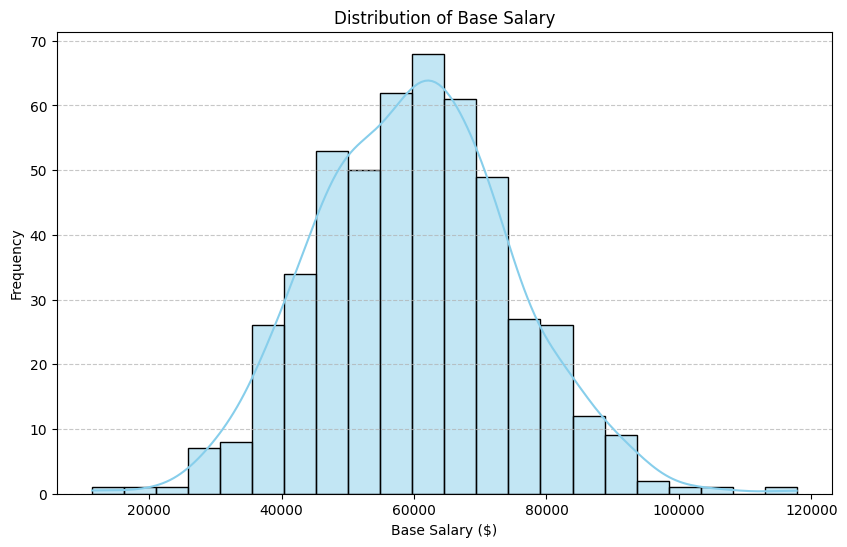

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

salary_std_figure = plt.figure(figsize=(10, 6))
sns.histplot(df['Base_Salary'], kde=True, color='skyblue')
plt.title('Distribution of Base Salary')
plt.xlabel('Base Salary ($)')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()